# Module 1: How an LLM works, seen through GPT-2
Companion to `docs/01_big_picture.html`. We use the real GPT-2 (124M parameters, Radford et al. 2019) as a specimen and take it apart.
Everything runs on CPU. First run downloads ~500 MB of weights.

In [1]:
import torch, math
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
torch.manual_seed(0)
tok = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager").eval()  # eager so we can read attention weights
print(f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

/home/ayush/llm_learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 4858.93it/s]

124.4M parameters


## 1. Text becomes integers
The model never sees characters or words, only token ids from a fixed vocabulary (50,257 entries, built by byte-pair encoding; module 2).

In [2]:
text = "The cat sat on the mat. Unbelievably, tokenization is weird!"
ids = tok.encode(text)
print(ids)
print([tok.decode([i]) for i in ids])

[464, 3797, 3332, 319, 262, 2603, 13, 791, 6667, 11203, 1346, 11, 11241, 1634, 318, 7650, 0]
['The', ' cat', ' sat', ' on', ' the', ' mat', '.', ' Un', 'bel', 'iev', 'ably', ',', ' token', 'ization', ' is', ' weird', '!']


**Try:** change the text. Add leading spaces, emoji, a long rare word, some code. Which strings cost many tokens?

## 2. The model outputs a probability distribution over the next token

In [3]:
def next_token_probs(prompt):
    ids = tok(prompt, return_tensors="pt").input_ids
    with torch.no_grad():
        logits = model(ids).logits[0, -1]      # (vocab,) scores for the position after the last token
    return torch.softmax(logits, dim=-1)

def show_top(prompt, k=10):
    p = next_token_probs(prompt)
    top = torch.topk(p, k)
    for pr, i in zip(top.values, top.indices):
        print(f"{pr:.3f}  {tok.decode([i])!r}")

show_top("The capital of France is")

0.085  ' the'
0.048  ' now'
0.046  ' a'
0.032  ' France'
0.032  ' Paris'
0.027  ' in'
0.026  ' also'
0.024  ' not'
0.023  ' home'
0.016  ' still'


In [4]:
show_top("I put the milk in the")

0.053  ' fridge'
0.039  ' bowl'
0.035  ' microwave'
0.032  ' milk'
0.032  ' oven'
0.030  ' freezer'
0.027  ' water'
0.026  ' refrigerator'
0.022  ' pan'
0.020  ' blender'


## 3. Generation is just a loop
Pick a token, append it, run the model again. We write it by hand instead of calling `model.generate`.

In [5]:
def generate(prompt, n=30, temperature=1.0, greedy=False):
    ids = tok(prompt, return_tensors="pt").input_ids
    for _ in range(n):
        with torch.no_grad():
            logits = model(ids).logits[0, -1]
        if greedy:
            nxt = logits.argmax()
        else:
            nxt = torch.multinomial(torch.softmax(logits / temperature, -1), 1)[0]
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)
    return tok.decode(ids[0])

print("GREEDY:", generate("In a shocking finding, scientists discovered", greedy=True))
for T in (0.3, 1.0, 1.5):
    print(f"\nT={T}:", generate("In a shocking finding, scientists discovered", temperature=T))

GREEDY: In a shocking finding, scientists discovered that the brain of a man who had been diagnosed with schizophrenia had a higher level of dopamine than that of a woman who had not.

The



T=0.3: In a shocking finding, scientists discovered that the brain of a mouse that is genetically similar to the one that was genetically identical to the one that was genetically identical to the one that was genetically



T=1.0: In a shocking finding, scientists discovered the hormone responsible in a large hematite tooth that hides behind a tiny drum.

The researchers suggest being prepared to remove the tooth and the



T=1.5: In a shocking finding, scientists discovered that research revenue for universities uses get a difficult credit tied to the whims of living forces' expanded lifestyles any time the clustering theory provided a discount for


Low temperature and greedy decoding tend to repeat themselves (watch T=0.3 loop); high temperature drifts into nonsense. Module 9 covers top-k, top-p and other fixes.

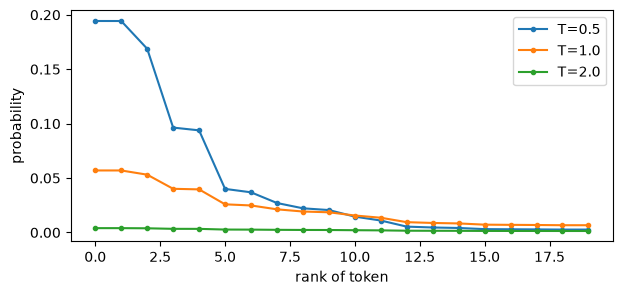

In [6]:
# How temperature reshapes the same distribution
logits = model(tok("The best programming language is", return_tensors="pt").input_ids).logits[0, -1].detach()
fig, ax = plt.subplots(figsize=(7, 3))
for T in (0.5, 1.0, 2.0):
    p = torch.softmax(logits / T, -1).sort(descending=True).values[:20]
    ax.plot(p, marker="o", ms=3, label=f"T={T}")
ax.set_xlabel("rank of token"); ax.set_ylabel("probability"); ax.legend(); plt.show()

## 4. Training objective: how surprised is the model by real text?
Pretraining minimises the average negative log-probability of each actual next token (cross-entropy). Perplexity = exp(loss).

In [7]:
def token_surprisals(text):
    ids = tok(text, return_tensors="pt").input_ids
    with torch.no_grad():
        logits = model(ids).logits[0, :-1]
    logp = torch.log_softmax(logits, -1)
    nll = -logp[torch.arange(ids.shape[1]-1), ids[0, 1:]]
    return [tok.decode([i]) for i in ids[0, 1:]], nll

for t in ["The quick brown fox jumps over the lazy dog.",
          "Dog lazy the over jumps fox brown quick The."]:
    toks, nll = token_surprisals(t)
    print(f"perplexity {math.exp(nll.mean()):8.1f}  | {t}")

toks, nll = token_surprisals("The quick brown fox jumps over the lazy dog.")
print()
for t, n in zip(toks, nll): print(f"{n:5.2f} nats  {t!r}")

perplexity    162.5  | The quick brown fox jumps over the lazy dog.
perplexity  10500.6  | Dog lazy the over jumps fox brown quick The.

 8.71 nats  ' quick'
 8.90 nats  ' brown'
 6.26 nats  ' fox'
 4.86 nats  ' jumps'
 2.75 nats  ' over'
 0.86 nats  ' the'
 7.25 nats  ' lazy'
 3.82 nats  ' dog'
 2.41 nats  '.'


Per-token surprise is highest where the continuation is least predictable, and the scrambled sentence is far more surprising. Note the first token has no prediction (nothing precedes it).

## 5. Anatomy: where do the 124M parameters live?

In [8]:
from collections import defaultdict
groups = defaultdict(int)
for name, p in model.named_parameters():
    key = ("token embedding" if "wte" in name else "position embedding" if "wpe" in name
           else "attention" if ".attn." in name else "MLP" if ".mlp." in name
           else "layernorm" if "ln" in name else name)
    groups[key] += p.numel()
for k, v in sorted(groups.items(), key=lambda kv: -kv[1]):
    print(f"{k:20s} {v/1e6:6.1f}M")
print(model.config.n_layer, "layers,", model.config.n_head, "heads, d_model =", model.config.n_embd)

MLP                    56.7M
token embedding        38.6M
attention              28.3M
position embedding      0.8M
layernorm               0.0M
12 layers, 12 heads, d_model = 768


The output layer shares weights with the token embedding (weight tying), so it adds no parameters. Roughly two thirds of the transformer block parameters are in the MLP, one third in attention.

## 6. Peek inside: attention patterns
GPT-2 can return its attention weights. Each head decides, for every token, which earlier tokens to read from.

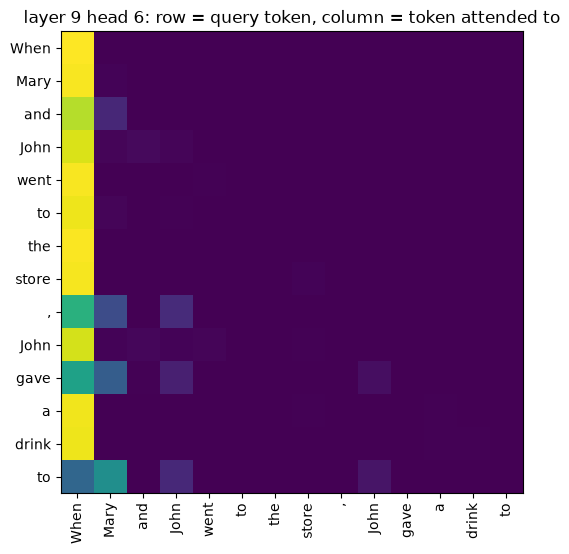

0.446  ' Mary'
0.212  ' them'
0.071  ' the'
0.060  ' John'
0.045  ' her'
0.012  ' his'
0.010  ' their'
0.010  ' a'
0.007  ' Joseph'
0.006  ' all'


In [9]:
text = "When Mary and John went to the store, John gave a drink to"
inputs = tok(text, return_tensors="pt")
with torch.no_grad():
    out = model(**inputs, output_attentions=True)
labels = [tok.decode([i]) for i in inputs.input_ids[0]]
layer, head = 9, 6   # a "name mover" head from Wang et al. 2022 (IOI circuit)
A = out.attentions[layer][0, head]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(A, cmap="viridis")
ax.set_xticks(range(len(labels)), labels, rotation=90); ax.set_yticks(range(len(labels)), labels)
ax.set_title(f"layer {layer} head {head}: row = query token, column = token attended to"); plt.show()
show_top(text)

The lower triangle is the causal mask: a token can't look ahead. Scan other `(layer, head)` pairs. Some heads attend to the previous token, some to the first token, a few to names, which is the circuit studied in *Interpretability in the Wild* (Wang et al. 2022; optional interpretability module).

## Exercises
1. Find the shortest prompt for which GPT-2 predicts a specific word with > 50% probability.
2. Compare perplexity of English, German, and Python code. Why do they differ?
3. Implement top-k sampling in `generate`.
4. Measure time per generated token as the prompt grows. What is the cost of re-running the whole prefix each step? (This motivates the KV cache, module 8.)